# Transcript usage

Test condition-associated changes in within-gene transcript proportions.


In [1]:
import json
import os
import shutil
import subprocess
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr

REFERENCE = 'Unaffected'
TEST = 'ASD'
ALPHA = 0.05
MIN_COUNT = 10
MIN_PROPORTION = 0.1
MIN_SAMPLES = 3
N_WORKERS = min(4, os.cpu_count() or 1)
FRACTIONS = {
    'input': ('Input', 'input'),
    'monosome': ('Monosome', 'mono'),
    'polysome': ('Polysome', 'poly'),
}
ANALYSES = (*FRACTIONS, 'redistribution')
LABELS = {
    'input': 'Input',
    'monosome': 'Monosome',
    'polysome': 'Polysome',
    'redistribution': 'Redistribution',
}
GENE_ABUNDANCE_FILES = {
    'input': 'inputDifferentialExpression.tsv',
    'monosome': 'monosomeDifferentialAbundance.tsv',
    'polysome': 'polysomeDifferentialAbundance.tsv',
    'redistribution': 'polysomeMonosome.tsv',
}
TRANSCRIPT_ABUNDANCE_FILES = {
    'input': 'inputDifferentialTranscriptAbundance.tsv',
    'monosome': 'monosomeDifferentialTranscriptAbundance.tsv',
    'polysome': 'polysomeDifferentialTranscriptAbundance.tsv',
    'redistribution': 'transcriptRedistribution.tsv',
}

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate inputs and verify the R environment.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data directory.')


def find_rscript() -> Path:
    executable = os.environ.get('RSCRIPT') or shutil.which('Rscript')
    if not executable:
        raise FileNotFoundError('Rscript was not found on PATH.')
    path = Path(executable).resolve()
    if not path.is_file():
        raise FileNotFoundError(f'Rscript was not found: {path}')
    return path


def r_environment() -> dict[str, str]:
    environment = os.environ.copy()
    for variable in ('LANG', 'LC_ALL', 'LC_CTYPE', 'LC_COLLATE'):
        environment.pop(variable, None)
    return environment


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
SCRIPT_PATH = ROOT / 'scripts' / 'dtu.R'
R_SCRIPT = find_rscript()
WORK_DIR = Path(tempfile.mkdtemp(prefix = 'polysomeDtu_'))
R_OUTPUT_DIR = WORK_DIR / 'rOutput'
R_OUTPUT_DIR.mkdir()
RESULTS_DIR.mkdir(exist_ok = True)

metadata = pd.read_csv(DATA_DIR / 'metadata.tsv', sep = '\t', dtype = 'string')
metadata = metadata.set_index('sampleId')
metadata['condition'] = pd.Categorical(
    metadata['condition'],
    categories = [REFERENCE, TEST],
)
sample_ids = metadata.index.tolist()

r_version = subprocess.run(
    [str(R_SCRIPT), '--version'],
    capture_output = True,
    text = True,
    check = True,
    env = r_environment(),
)
r_version = (r_version.stderr or r_version.stdout).strip()

if metadata['condition'].isna().any():
    raise ValueError('Metadata contains an unexpected condition.')
if metadata['condition'].value_counts().min() != MIN_SAMPLES:
    raise ValueError('The DTU filter requires three participants per condition.')
if not SCRIPT_PATH.is_file():
    raise FileNotFoundError('The DTU R script is missing.')

configuration = pd.DataFrame({
    'setting': [
        'R',
        'workers',
        'minimum transcript count',
        'minimum transcript proportion',
        'minimum supporting libraries',
        'stage-wise OFDR',
    ],
    'value': [
        r_version,
        N_WORKERS,
        MIN_COUNT,
        MIN_PROPORTION,
        MIN_SAMPLES,
        ALPHA,
    ],
})
display(configuration)


,setting,value
0,R,Rscript (R) version 4.6.1 (2026-06-24)
1,workers,4
2,minimum transcript count,10
3,minimum transcript proportion,0.1
4,minimum supporting libraries,3
5,stage-wise OFDR,0.05


In [3]:
# Load and align the Salmon transcript estimates selected by the metadata.

raw_counts = {}
raw_tpm = {}
raw_lengths = {}
quantification_records = []
parent_genes = None
gene_names = None

for analysis, (folder, prefix) in FRACTIONS.items():
    count_path = DATA_DIR / folder / 'salmon.merged.transcript_counts.tsv'
    tpm_path = DATA_DIR / folder / 'salmon.merged.transcript_tpm.tsv'
    length_path = DATA_DIR / folder / 'salmon.merged.transcript_lengths.tsv'
    gene_path = DATA_DIR / folder / 'salmon.merged.gene_counts.tsv'
    count_table = pd.read_csv(count_path, sep = '\t')
    tpm_table = pd.read_csv(tpm_path, sep = '\t')
    length_table = pd.read_csv(length_path, sep = '\t')
    gene_table = pd.read_csv(gene_path, sep = '\t')
    columns = [f'{prefix}{sample_id}' for sample_id in sample_ids]

    if not count_table[['tx', 'gene_id']].equals(
        tpm_table[['tx', 'gene_id']]
    ):
        raise ValueError(f'Count and TPM identifiers disagree in {folder}.')
    if not count_table[['tx', 'gene_id']].equals(
        length_table[['tx', 'gene_id']]
    ):
        raise ValueError(f'Count and length identifiers disagree in {folder}.')
    if not count_table['tx'].is_unique:
        raise ValueError(f'Transcript identifiers are duplicated in {folder}.')

    current_parent_genes = count_table.set_index('tx')['gene_id']
    current_gene_names = gene_table.set_index('gene_id')['gene_name']

    if parent_genes is None:
        parent_genes = current_parent_genes
        gene_names = current_gene_names
    elif not parent_genes.equals(current_parent_genes):
        raise ValueError(f'Transcript-to-gene mappings disagree in {folder}.')
    if not gene_names.equals(current_gene_names):
        raise ValueError(f'Gene annotations disagree in {folder}.')

    count_values = count_table.set_index('tx')[columns]
    tpm_values = tpm_table.set_index('tx')[columns]
    length_values = length_table.set_index('tx')[columns]
    count_values.columns = sample_ids
    tpm_values.columns = sample_ids
    length_values.columns = sample_ids

    for label, values in (
        ('counts', count_values),
        ('TPM', tpm_values),
        ('effective lengths', length_values),
    ):
        array = values.to_numpy(dtype = 'float64')
        if not np.isfinite(array).all() or (array < 0).any():
            raise ValueError(f'{folder} {label} must be finite and nonnegative.')

    transcript_sums = count_values.groupby(parent_genes, sort = False).sum()
    gene_values = gene_table.set_index('gene_id').loc[
        transcript_sums.index,
        columns,
    ]
    maximum_sum_error = np.abs(
        transcript_sums.to_numpy() - gene_values.to_numpy()
    ).max()

    if maximum_sum_error > 1e-6:
        raise ValueError(f'{folder} transcript and gene counts disagree.')

    quantification_records.append({
        'analysis': analysis,
        'transcripts': len(count_values),
        'parentGenes': parent_genes.nunique(),
        'maximumGeneSumError': maximum_sum_error,
        'minimumTpmSum': tpm_values.sum(axis = 0).min(),
        'maximumTpmSum': tpm_values.sum(axis = 0).max(),
        'inferentialReplicatesAvailable': False,
    })
    raw_counts[analysis] = count_values
    raw_tpm[analysis] = tpm_values
    raw_lengths[analysis] = length_values

quantification_audit = pd.DataFrame(quantification_records)
display(quantification_audit)


,analysis,transcripts,parentGenes,maximumGeneSumError,minimumTpmSum,maximumTpmSum,inferentialReplicatesAvailable
0,input,646577,78941,2.328306e-10,999999.999885,1.000000e+06,False
1,monosome,646577,78941,1.047738e-09,999999.999880,1.000000e+06,False
2,polysome,646577,78941,1.164153e-10,999999.999924,1.000000e+06,False


In [4]:
# Reconstruct tximport dtuScaledTPM counts and apply the canonical DTU filter.


def dtu_scaled_counts(
    counts: pd.DataFrame,
    tpm: pd.DataFrame,
    lengths: pd.DataFrame,
) -> pd.DataFrame:
    mean_length = lengths.mean(axis = 1)
    gene_median_length = mean_length.groupby(
        parent_genes,
        sort = False,
    ).transform('median')
    scaled = tpm.mul(gene_median_length, axis = 0)
    scaled = scaled.mul(counts.sum(axis = 0) / scaled.sum(axis = 0), axis = 1)
    return scaled


def canonical_dtu_filter(values: pd.DataFrame) -> pd.Series:
    gene_count = values.groupby(parent_genes, sort = False).transform('sum')
    gene_keep = gene_count.ge(MIN_COUNT).all(axis = 1)
    count_keep = values.ge(MIN_COUNT).sum(axis = 1).ge(MIN_SAMPLES)
    filtered_gene_count = values.loc[count_keep].groupby(
        parent_genes.loc[count_keep],
        sort = False,
    ).transform('sum')
    proportion_keep = values.loc[count_keep].divide(
        filtered_gene_count.replace(0, np.nan)
    ).ge(MIN_PROPORTION).sum(axis = 1).ge(MIN_SAMPLES)
    keep = gene_keep & count_keep & proportion_keep.reindex(
        values.index,
        fill_value = False,
    )
    retained_transcripts = parent_genes.loc[keep].value_counts()
    return keep & parent_genes.map(retained_transcripts).ge(2)


def sample_table(analysis: str, columns: list[str]) -> pd.DataFrame:
    if analysis != 'redistribution':
        return pd.DataFrame({
            'sampleId': columns,
            'participantId': columns,
            'condition': metadata.loc[columns, 'condition'].astype('string').to_numpy(),
            'fraction': analysis,
        })
    records = []
    for fraction in ('monosome', 'polysome'):
        for sample_id in sample_ids:
            records.append({
                'sampleId': f'{sample_id}_{fraction}',
                'participantId': sample_id,
                'condition': str(metadata.loc[sample_id, 'condition']),
                'fraction': fraction,
            })
    return pd.DataFrame(records)


scaled_counts = {}
analysis_metadata = {}
filter_masks = {}
usage = {}
scaling_records = []
filter_records = []

for analysis in FRACTIONS:
    scaled_counts[analysis] = dtu_scaled_counts(
        raw_counts[analysis],
        raw_tpm[analysis],
        raw_lengths[analysis],
    )
    usage[analysis] = raw_tpm[analysis].divide(
        raw_tpm[analysis].groupby(parent_genes, sort = False).transform('sum')
        .replace(0, np.nan)
    )
    analysis_metadata[analysis] = sample_table(analysis, sample_ids)

redistribution_columns = [
    f'{sample_id}_{fraction}'
    for fraction in ('monosome', 'polysome')
    for sample_id in sample_ids
]
redistribution_counts = pd.concat(
    [raw_counts['monosome'], raw_counts['polysome']],
    axis = 1,
)
redistribution_tpm = pd.concat(
    [raw_tpm['monosome'], raw_tpm['polysome']],
    axis = 1,
)
redistribution_lengths = pd.concat(
    [raw_lengths['monosome'], raw_lengths['polysome']],
    axis = 1,
)
redistribution_counts.columns = redistribution_columns
redistribution_tpm.columns = redistribution_columns
redistribution_lengths.columns = redistribution_columns
scaled_counts['redistribution'] = dtu_scaled_counts(
    redistribution_counts,
    redistribution_tpm,
    redistribution_lengths,
)
analysis_metadata['redistribution'] = sample_table(
    'redistribution',
    redistribution_columns,
)

original_counts = {
    **raw_counts,
    'redistribution': redistribution_counts,
}
original_tpm = {
    **raw_tpm,
    'redistribution': redistribution_tpm,
}

for analysis in ANALYSES:
    scaled = scaled_counts[analysis]
    tpm_values = original_tpm[analysis]
    scaled_proportion = scaled.divide(
        scaled.groupby(parent_genes, sort = False).transform('sum')
        .replace(0, np.nan)
    )
    tpm_proportion = tpm_values.divide(
        tpm_values.groupby(parent_genes, sort = False).transform('sum')
        .replace(0, np.nan)
    )
    proportion_error = np.nanmax(
        np.abs(
            scaled_proportion.to_numpy()
            - tpm_proportion.to_numpy()
        )
    )
    library_sum_error = np.abs(
        scaled.sum(axis = 0) - original_counts[analysis].sum(axis = 0)
    ).max()
    keep = canonical_dtu_filter(scaled)
    filter_masks[analysis] = keep
    scaling_records.append({
        'analysis': analysis,
        'libraries': scaled.shape[1],
        'maximumLibrarySumError': library_sum_error,
        'maximumWithinGeneProportionError': proportion_error,
    })
    filter_records.append({
        'analysis': analysis,
        'inputGenes': parent_genes.nunique(),
        'inputTranscripts': len(parent_genes),
        'retainedGenes': parent_genes.loc[keep].nunique(),
        'retainedTranscripts': int(keep.sum()),
        'minimumGeneCount': MIN_COUNT,
        'minimumGeneSamples': scaled.shape[1],
        'minimumTranscriptCount': MIN_COUNT,
        'minimumTranscriptProportion': MIN_PROPORTION,
        'minimumTranscriptSamples': MIN_SAMPLES,
    })

    count_output = scaled.loc[keep].copy()
    count_output.insert(0, 'transcriptId', count_output.index)
    count_output.insert(
        0,
        'geneId',
        parent_genes.reindex(count_output['transcriptId']).to_numpy(),
    )
    count_output.to_csv(
        WORK_DIR / f'{analysis}Counts.tsv',
        sep = '\t',
        index = False,
    )
    analysis_metadata[analysis].to_csv(
        WORK_DIR / f'{analysis}Samples.tsv',
        sep = '\t',
        index = False,
    )

scaling_audit = pd.DataFrame(scaling_records)
filter_summary = pd.DataFrame(filter_records)

if scaling_audit['maximumLibrarySumError'].max() > 1e-5:
    raise ValueError('dtuScaledTPM counts do not preserve library totals.')
if scaling_audit['maximumWithinGeneProportionError'].max() > 1e-12:
    raise ValueError('dtuScaledTPM counts do not preserve TPM proportions.')

display(scaling_audit)
display(filter_summary)


,analysis,libraries,maximumLibrarySumError,maximumWithinGeneProportionError
0,input,6,1.490116e-08,4.440892e-16
1,monosome,6,1.490116e-08,3.330669e-16
2,polysome,6,0.000000e+00,3.330669e-16
3,redistribution,12,1.490116e-08,3.330669e-16


,analysis,inputGenes,inputTranscripts,retainedGenes,retainedTranscripts,minimumGeneCount,minimumGeneSamples,minimumTranscriptCount,minimumTranscriptProportion,minimumTranscriptSamples
0,input,78941,646577,10979,30587,10,6,10,0.1,3
1,monosome,78941,646577,11009,29603,10,6,10,0.1,3
2,polysome,78941,646577,11007,29627,10,6,10,0.1,3
3,redistribution,78941,646577,12895,43816,10,12,10,0.1,3


In [5]:
# Run one isolated satuRn and stageR analysis and verify its output contract.


def run_dtu(analysis: str) -> dict:
    command = [
        str(R_SCRIPT),
        str(SCRIPT_PATH),
        str(WORK_DIR / f'{analysis}Counts.tsv'),
        str(WORK_DIR / f'{analysis}Samples.tsv'),
        analysis,
        str(R_OUTPUT_DIR),
        str(N_WORKERS),
    ]
    start = time.perf_counter()
    completed = subprocess.run(
        command,
        cwd = ROOT,
        capture_output = True,
        text = True,
        env = r_environment(),
        check = False,
    )
    elapsed = time.perf_counter() - start

    if completed.returncode != 0:
        raise RuntimeError(
            f'{analysis} DTU failed:\n{completed.stdout}\n{completed.stderr}'
        )

    prefix = R_OUTPUT_DIR / analysis
    output = {
        'gene': pd.read_csv(f'{prefix}Gene.tsv', sep = '\t'),
        'transcript': pd.read_csv(f'{prefix}Transcript.tsv', sep = '\t'),
        'retained': pd.read_csv(f'{prefix}Retained.tsv', sep = '\t'),
        'summary': pd.read_csv(f'{prefix}Summary.tsv', sep = '\t'),
        'designFull': pd.read_csv(f'{prefix}DesignFull.tsv', sep = '\t'),
        'designNull': pd.read_csv(f'{prefix}DesignNull.tsv', sep = '\t'),
        'versions': pd.read_csv(f'{prefix}Versions.tsv', sep = '\t'),
        'warnings': pd.read_csv(f'{prefix}Warnings.tsv', sep = '\t'),
        'diagnosticPath': Path(f'{prefix}EmpiricalDiagnostics.pdf'),
        'sessionInfo': Path(f'{prefix}SessionInfo.txt').read_text(encoding = 'utf-8'),
        'messages': '\n'.join(
            value.strip()
            for value in (completed.stdout, completed.stderr)
            if value.strip()
        ),
        'seconds': elapsed,
    }
    expected = set(
        scaled_counts[analysis].index[filter_masks[analysis]]
    )
    observed = set(output['retained']['transcriptId'])
    expected_genes = set(parent_genes.reindex(list(expected)))

    if observed != expected:
        raise ValueError(f'{analysis} Python and R transcript sets disagree.')
    if set(output['gene']['geneId']) != expected_genes:
        raise ValueError(f'{analysis} gene result universe is incomplete.')
    if set(output['transcript']['transcriptId']) != expected:
        raise ValueError(f'{analysis} transcript result universe is incomplete.')
    if output['gene']['geneId'].duplicated().any():
        raise ValueError(f'{analysis} gene results are duplicated.')
    if output['transcript']['transcriptId'].duplicated().any():
        raise ValueError(f'{analysis} transcript results are duplicated.')
    if not output['designFull']['sampleId'].equals(
        analysis_metadata[analysis]['sampleId']
    ):
        raise ValueError(f'{analysis} design rows are misaligned.')
    model_summary = output['summary'].iloc[0]
    if int(model_summary['testDegreesOfFreedom']) != 1:
        raise ValueError(
            f'{analysis} does not test exactly one model coefficient.'
        )
    finite_df = output['transcript']['degreesOfFreedom'].dropna()
    if finite_df.empty or not finite_df.gt(0).all():
        raise ValueError(f'{analysis} has invalid transcript-level residual degrees.')
    usable = output['transcript']['fitUsable']
    if not output['transcript']['fitStatus'].eq('glm').equals(usable):
        raise ValueError(f'{analysis} fit-usability labels are inconsistent.')
    if int((~usable).sum()) != int(model_summary['fitErrorTranscripts']):
        raise ValueError(f'{analysis} fit-error counts are inconsistent.')
    if output['transcript'].loc[
        ~usable,
        'stageTranscriptAdjustedPValue',
    ].notna().any():
        raise ValueError(f'{analysis} assigned inference to a failed fit.')
    stage_gene_expected = output['transcript']['geneId'].map(
        output['gene'].set_index('geneId')['stageAdjustedPValue']
    )
    if not np.allclose(
        output['transcript']['stageGeneAdjustedPValue'],
        stage_gene_expected,
        equal_nan = True,
    ):
        raise ValueError(f'{analysis} stageR screening adjustments are misaligned.')
    transcript_significant = output['transcript'][
        'stageTranscriptAdjustedPValue'
    ].lt(ALPHA)
    if (
        transcript_significant
        & ~stage_gene_expected.lt(ALPHA)
    ).any():
        raise ValueError(f'{analysis} stageR confirmed an unscreened transcript.')
    if not output['diagnosticPath'].is_file():
        raise FileNotFoundError(f'{analysis} empirical-null diagnostics are missing.')
    return output


dtu = {}


In [6]:
# Test input RNA transcript usage.

dtu['input'] = run_dtu('input')
display(dtu['input']['summary'])
display(dtu['input']['gene'].sort_values('stageAdjustedPValue').head(15))


,analysis,testedGenes,testedTranscripts,modelRank,residualDegreesOfFreedom,testDegreesOfFreedom,fitErrorTranscripts,nonConvergedTranscripts,boundaryFitTranscripts,nonfiniteCoefficientTranscripts,undefinedGeneScreens,undefinedTranscriptPValues,stageSignificantGenes,stageSignificantTranscripts,warningCount
0,input,10979,30587,2,4,1,19,4,19,0,6,19,2,3,0


,geneId,minimumTranscriptPValue,screenInputPValue,stageAdjustedPValue,transcriptCount,finiteTranscriptPValues,fitErrorTranscripts
6857,ENSG00000150991.18,1.099251e-06,1.099251e-06,0.016801,3,3,0
1939,ENSG00000168028.17,9.564258e-07,9.564258e-07,0.029236,2,2,0
643,ENSG00000159164.12,7.919808e-06,7.919808e-06,0.060523,3,3,0
7749,ENSG00000293320.1,7.450414e-06,7.450414e-06,0.075914,2,2,0
3532,ENSG00000112473.21,2.620654e-05,2.620654e-05,0.080106,2,2,0
7841,ENSG00000129925.13,1.406762e-05,1.406762e-05,0.086003,3,3,0
993,ENSG00000143742.16,2.587730e-05,2.587730e-05,0.087888,2,2,0
6576,ENSG00000197728.13,2.505847e-05,2.505847e-05,0.095746,2,2,0
9466,ENSG00000172687.16,2.350762e-05,2.350762e-05,0.102652,2,2,0
5132,ENSG00000148204.14,2.046891e-05,2.046891e-05,0.104280,5,5,0


In [7]:
# Test monosome-associated RNA transcript usage.

dtu['monosome'] = run_dtu('monosome')
display(dtu['monosome']['summary'])
display(dtu['monosome']['gene'].sort_values('stageAdjustedPValue').head(15))


,analysis,testedGenes,testedTranscripts,modelRank,residualDegreesOfFreedom,testDegreesOfFreedom,fitErrorTranscripts,nonConvergedTranscripts,boundaryFitTranscripts,nonfiniteCoefficientTranscripts,undefinedGeneScreens,undefinedTranscriptPValues,stageSignificantGenes,stageSignificantTranscripts,warningCount
0,monosome,11009,29603,2,4,1,24,12,24,0,4,24,0,0,0


,geneId,minimumTranscriptPValue,screenInputPValue,stageAdjustedPValue,transcriptCount,finiteTranscriptPValues,fitErrorTranscripts
7738,ENSG00000293320.1,0.000003,0.000003,0.099369,2,2,0
8,ENSG00000188290.13,0.000029,0.000029,0.431001,3,3,0
10375,ENSG00000184702.22,0.000174,0.000174,0.643701,3,3,0
9779,ENSG00000142541.20,0.000162,0.000162,0.686186,3,3,0
1033,ENSG00000143742.16,0.000228,0.000228,0.749988,2,2,0
22,ENSG00000175756.16,0.000160,0.000160,0.790505,3,3,0
2748,ENSG00000164109.16,0.000275,0.000275,0.812879,3,3,0
1834,ENSG00000168505.8,0.000337,0.000337,0.829328,3,3,0
1438,ENSG00000144026.16,0.000316,0.000316,0.850453,2,2,0
6737,ENSG00000139428.14,0.000160,0.000160,0.948527,3,3,0


In [8]:
# Test polysome-associated RNA transcript usage.

dtu['polysome'] = run_dtu('polysome')
display(dtu['polysome']['summary'])
display(dtu['polysome']['gene'].sort_values('stageAdjustedPValue').head(15))


,analysis,testedGenes,testedTranscripts,modelRank,residualDegreesOfFreedom,testDegreesOfFreedom,fitErrorTranscripts,nonConvergedTranscripts,boundaryFitTranscripts,nonfiniteCoefficientTranscripts,undefinedGeneScreens,undefinedTranscriptPValues,stageSignificantGenes,stageSignificantTranscripts,warningCount
0,polysome,11007,29627,2,4,1,122,42,122,0,33,122,0,0,2


,geneId,minimumTranscriptPValue,screenInputPValue,stageAdjustedPValue,transcriptCount,finiteTranscriptPValues,fitErrorTranscripts
4689,ENSG00000079102.20,0.974190,0.974190,0.999654,2,2,0
4280,ENSG00000170667.18,0.974051,0.974051,0.999741,2,2,0
9381,ENSG00000104889.9,0.973906,0.973906,0.999828,2,2,0
8616,ENSG00000278540.6,0.973490,0.973490,0.999908,2,2,0
6264,ENSG00000248712.10,0.973065,0.973065,0.999987,2,2,0
10991,ENSG00000114374.15,0.019622,0.019622,1.000000,3,3,0
10990,ENSG00000291034.2,0.483206,0.483206,1.000000,3,3,0
10989,ENSG00000293442.2,0.728124,0.728124,1.000000,2,2,0
10988,ENSG00000092377.16,0.736142,0.736142,1.000000,2,2,0
10987,ENSG00000067646.14,0.430559,0.430559,1.000000,2,2,0


In [9]:
# Test participant-paired monosome-to-polysome transcript redistribution.

dtu['redistribution'] = run_dtu('redistribution')
display(dtu['redistribution']['summary'])
display(
    dtu['redistribution']['gene'].sort_values('stageAdjustedPValue').head(15)
)


,analysis,testedGenes,testedTranscripts,modelRank,residualDegreesOfFreedom,testDegreesOfFreedom,fitErrorTranscripts,nonConvergedTranscripts,boundaryFitTranscripts,nonfiniteCoefficientTranscripts,undefinedGeneScreens,undefinedTranscriptPValues,stageSignificantGenes,stageSignificantTranscripts,warningCount
0,redistribution,12895,43816,8,4,1,814,550,814,0,97,876,0,0,1


,geneId,minimumTranscriptPValue,screenInputPValue,stageAdjustedPValue,transcriptCount,finiteTranscriptPValues,fitErrorTranscripts
11859,ENSG00000198026.10,0.000031,0.000031,0.436975,4,4,0
3158,ENSG00000109332.22,0.000025,0.000025,0.538386,5,5,0
8950,ENSG00000074696.15,0.000051,0.000051,0.542235,4,4,0
2499,ENSG00000144749.16,0.000087,0.000087,0.624988,5,5,0
8642,ENSG00000165934.15,0.000109,0.000109,0.665705,3,2,1
8885,ENSG00000128989.13,0.000087,0.000087,0.745779,3,3,0
4928,ENSG00000127995.19,0.000019,0.000019,0.825927,3,3,0
7755,ENSG00000293429.1,0.980357,0.980357,0.999894,3,3,0
590,ENSG00000067208.19,0.976713,0.976713,0.999911,3,1,2
1575,ENSG00000087338.7,0.973530,0.973530,0.999928,3,1,2


In [10]:
# Calculate observed proportion effects and integrate abundance-model support.

condition_samples = {
    condition: metadata.index[metadata['condition'].eq(condition)].tolist()
    for condition in (REFERENCE, TEST)
}
gene_results = {}
transcript_results = {}


def add_fraction_effects(analysis: str, table: pd.DataFrame) -> pd.DataFrame:
    result = table.copy().set_index('transcriptId')
    ids = result.index
    values = usage[analysis].reindex(ids)
    result['unaffectedMeanProportion'] = values[
        condition_samples[REFERENCE]
    ].mean(axis = 1)
    result['asdMeanProportion'] = values[condition_samples[TEST]].mean(axis = 1)
    result['deltaProportion'] = (
        result['asdMeanProportion'] - result['unaffectedMeanProportion']
    )
    result['structuralZero'] = (
        raw_counts[analysis].reindex(ids)[condition_samples[REFERENCE]]
        .sum(axis = 1).eq(0)
        | raw_counts[analysis].reindex(ids)[condition_samples[TEST]]
        .sum(axis = 1).eq(0)
    )
    return result


def add_redistribution_effects(table: pd.DataFrame) -> pd.DataFrame:
    result = table.copy().set_index('transcriptId')
    ids = result.index
    mono = usage['monosome'].reindex(ids)
    poly = usage['polysome'].reindex(ids)
    for condition, label in ((REFERENCE, 'unaffected'), (TEST, 'asd')):
        samples = condition_samples[condition]
        result[f'{label}MonosomeMeanProportion'] = mono[samples].mean(axis = 1)
        result[f'{label}PolysomeMeanProportion'] = poly[samples].mean(axis = 1)
        result[f'{label}PolysomeMonosomeDelta'] = (
            result[f'{label}PolysomeMeanProportion']
            - result[f'{label}MonosomeMeanProportion']
        )
    result['deltaProportion'] = (
        result['asdPolysomeMonosomeDelta']
        - result['unaffectedPolysomeMonosomeDelta']
    )
    zero_patterns = []
    for fraction in ('monosome', 'polysome'):
        for condition in (REFERENCE, TEST):
            zero_patterns.append(
                raw_counts[fraction].reindex(ids)[condition_samples[condition]]
                .sum(axis = 1).eq(0)
            )
    result['structuralZero'] = pd.concat(zero_patterns, axis = 1).any(axis = 1)
    return result


for analysis in ANALYSES:
    transcript = dtu[analysis]['transcript']
    if analysis == 'redistribution':
        transcript = add_redistribution_effects(transcript)
    else:
        transcript = add_fraction_effects(analysis, transcript)

    gene = dtu[analysis]['gene'].copy().set_index('geneId')
    transcript['geneName'] = transcript['geneId'].map(gene_names)
    transcript['geneStageAdjustedPValue'] = transcript['geneId'].map(
        gene['stageAdjustedPValue']
    )
    transcript['geneSignificant'] = transcript[
        'geneStageAdjustedPValue'
    ].lt(ALPHA)
    transcript['transcriptSignificant'] = transcript[
        'stageTranscriptAdjustedPValue'
    ].lt(ALPHA)

    transcript_abundance = pd.read_csv(
        RESULTS_DIR / TRANSCRIPT_ABUNDANCE_FILES[analysis],
        sep = '\t',
    ).set_index('transcriptId')
    transcript['abundanceTested'] = transcript.index.isin(
        transcript_abundance.index
    )
    transcript['abundanceLog2FoldChange'] = transcript.index.map(
        transcript_abundance['log2FoldChange']
    )
    transcript['abundanceAdjustedPValue'] = transcript.index.map(
        transcript_abundance['adjustedPValue']
    )
    transcript['abundanceFdr'] = transcript[
        'abundanceAdjustedPValue'
    ].lt(ALPHA)

    dominant = transcript.loc[
        transcript['deltaProportion'].abs().groupby(transcript['geneId']).idxmax()
    ].copy()
    dominant['transcriptId'] = dominant.index
    dominant = dominant.set_index('geneId')
    gene['geneName'] = gene.index.map(gene_names)
    gene['dominantTranscriptId'] = dominant['transcriptId']
    gene['dominantDeltaProportion'] = dominant['deltaProportion']
    gene['maximumAbsDeltaProportion'] = dominant['deltaProportion'].abs()
    gene['significant'] = gene['stageAdjustedPValue'].lt(ALPHA)
    gene['significantTranscriptCount'] = transcript.groupby('geneId')[
        'transcriptSignificant'
    ].sum().reindex(gene.index, fill_value = 0)
    gene['confirmed'] = gene['significantTranscriptCount'].gt(0)
    gene['significantStructuralZeroTranscriptCount'] = transcript.loc[
        transcript['transcriptSignificant']
    ].groupby('geneId')['structuralZero'].sum().reindex(gene.index, fill_value = 0)

    gene_abundance = pd.read_csv(
        RESULTS_DIR / GENE_ABUNDANCE_FILES[analysis],
        sep = '\t',
    ).set_index('geneId')
    gene['abundanceLog2FoldChange'] = gene.index.map(
        gene_abundance['log2FoldChange']
    )
    gene['abundanceAdjustedPValue'] = gene.index.map(
        gene_abundance['adjustedPValue']
    )
    gene['abundanceFdr'] = gene['abundanceAdjustedPValue'].lt(ALPHA)
    gene['usageOnly'] = gene['significant'] & ~gene['abundanceFdr']

    gene_results[analysis] = gene
    transcript_results[analysis] = transcript


In [11]:
# Compare DTU across layers and audit stage-wise discoveries.

gene_index = pd.Index(
    sorted(set().union(*(set(table.index) for table in gene_results.values()))),
    name = 'geneId',
)
transcript_index = pd.Index(
    sorted(
        set().union(*(set(table.index) for table in transcript_results.values()))
    ),
    name = 'transcriptId',
)
gene_comparison = pd.DataFrame(index = gene_index)
gene_comparison['geneName'] = gene_comparison.index.map(gene_names)
transcript_comparison = pd.DataFrame(index = transcript_index)
transcript_comparison['parentGeneId'] = parent_genes.reindex(transcript_index)
transcript_comparison['geneName'] = transcript_comparison[
    'parentGeneId'
].map(gene_names)

gene_metrics = (
    'minimumTranscriptPValue',
    'screenInputPValue',
    'stageAdjustedPValue',
    'dominantTranscriptId',
    'dominantDeltaProportion',
    'maximumAbsDeltaProportion',
    'significant',
    'confirmed',
    'significantTranscriptCount',
    'abundanceAdjustedPValue',
    'abundanceFdr',
    'usageOnly',
)
transcript_metrics = (
    'pValue',
    'stageTranscriptAdjustedPValue',
    'deltaProportion',
    'geneSignificant',
    'transcriptSignificant',
    'modelConverged',
    'boundaryFit',
    'fitUsable',
    'structuralZero',
    'abundanceAdjustedPValue',
    'abundanceFdr',
)

for analysis in ANALYSES:
    for metric in gene_metrics:
        column = f'{analysis}{metric[0].upper()}{metric[1:]}'
        gene_comparison[column] = gene_results[analysis][metric].reindex(
            gene_index
        )
    for metric in transcript_metrics:
        column = f'{analysis}{metric[0].upper()}{metric[1:]}'
        transcript_comparison[column] = transcript_results[analysis][
            metric
        ].reindex(transcript_index)

gene_fdr_columns = [f'{analysis}Significant' for analysis in ANALYSES]
gene_comparison['dtuLayerCount'] = gene_comparison[
    gene_fdr_columns
].fillna(False).sum(axis = 1)
gene_comparison['dtuLayers'] = gene_comparison[gene_fdr_columns].apply(
    lambda row: ';'.join(
        analysis
        for analysis, column in zip(ANALYSES, gene_fdr_columns, strict = True)
        if bool(row.get(column, False))
    ),
    axis = 1,
)

common_genes = pd.Index(
    sorted(set.intersection(*(set(table.index) for table in gene_results.values()))),
    name = 'geneId',
)
common_fdr = gene_comparison.loc[common_genes, gene_fdr_columns].fillna(False)
common_fdr.columns = list(ANALYSES)
selected_fdr = common_fdr.loc[common_fdr.any(axis = 1)]
gene_fdr_overlap = selected_fdr.value_counts().rename('genes').reset_index()
gene_fdr_overlap['universeGenes'] = len(common_genes)
gene_fdr_overlap['signature'] = gene_fdr_overlap.apply(
    lambda row: ' + '.join(
        LABELS[analysis] for analysis in ANALYSES if row[analysis]
    ),
    axis = 1,
)
gene_fdr_overlap = gene_fdr_overlap.sort_values(
    ['genes', 'signature'],
    ascending = [False, True],
)

correlation_records = []
for x_analysis in ANALYSES:
    for y_analysis in ANALYSES:
        complete = transcript_comparison[[
            f'{x_analysis}DeltaProportion',
            f'{y_analysis}DeltaProportion',
        ]].dropna()
        correlation = spearmanr(complete.iloc[:, 0], complete.iloc[:, 1])
        correlation_records.append({
            'xAnalysis': x_analysis,
            'yAnalysis': y_analysis,
            'transcripts': len(complete),
            'spearmanRho': correlation.statistic,
            'pValue': correlation.pvalue,
        })

layer_correlation = pd.DataFrame(correlation_records)
correlation_matrix = layer_correlation.pivot(
    index = 'yAnalysis',
    columns = 'xAnalysis',
    values = 'spearmanRho',
).reindex(index = ANALYSES, columns = ANALYSES)

summary_records = []
candidate_records = []

for analysis in ANALYSES:
    gene = gene_results[analysis]
    transcript = transcript_results[analysis]
    model_summary = dtu[analysis]['summary'].iloc[0]
    significant_gene = gene['significant']
    significant_transcript = transcript['transcriptSignificant']
    summary_records.append({
        'analysis': analysis,
        'testedGenes': len(gene),
        'testedTranscripts': len(transcript),
        'modelRank': int(model_summary['modelRank']),
        'residualDegreesOfFreedom': int(
            model_summary['residualDegreesOfFreedom']
        ),
        'fitErrorTranscripts': int(model_summary['fitErrorTranscripts']),
        'nonConvergedTranscripts': int(
            model_summary['nonConvergedTranscripts']
        ),
        'boundaryFitTranscripts': int(
            model_summary['boundaryFitTranscripts']
        ),
        'nonfiniteCoefficientTranscripts': int(
            model_summary['nonfiniteCoefficientTranscripts']
        ),
        'undefinedGeneScreens': int(model_summary['undefinedGeneScreens']),
        'undefinedTranscriptPValues': int(
            model_summary['undefinedTranscriptPValues']
        ),
        'warningCount': int(model_summary['warningCount']),
        'stageSignificantGenes': int(significant_gene.sum()),
        'confirmedGenes': int(gene['confirmed'].sum()),
        'stageSignificantTranscripts': int(significant_transcript.sum()),
        'significantStructuralZeroTranscripts': int(
            (significant_transcript & transcript['structuralZero']).sum()
        ),
        'abundanceFdrGenes': int((significant_gene & gene['abundanceFdr']).sum()),
        'usageOnlyGenes': int(gene['usageOnly'].sum()),
        'seconds': dtu[analysis]['seconds'],
    })
    candidates = gene.loc[significant_gene].copy()
    candidates.insert(0, 'analysis', analysis)
    candidate_records.append(candidates.reset_index())

dtu_summary = pd.DataFrame(summary_records)
dtu_candidates = pd.concat(candidate_records, ignore_index = True)
dtu_candidates = dtu_candidates.sort_values(
    ['stageAdjustedPValue', 'maximumAbsDeltaProportion'],
    ascending = [True, False],
)

display(dtu_summary)
display(gene_fdr_overlap)
display(dtu_candidates.head(30))


,analysis,testedGenes,testedTranscripts,modelRank,residualDegreesOfFreedom,fitErrorTranscripts,nonConvergedTranscripts,boundaryFitTranscripts,nonfiniteCoefficientTranscripts,undefinedGeneScreens,undefinedTranscriptPValues,warningCount,stageSignificantGenes,confirmedGenes,stageSignificantTranscripts,significantStructuralZeroTranscripts,abundanceFdrGenes,usageOnlyGenes,seconds
0,input,10979,30587,2,4,19,4,19,0,6,19,0,2,2,3,0,0,2,43.271721
1,monosome,11009,29603,2,4,24,12,24,0,4,24,0,0,0,0,0,0,0,42.669839
2,polysome,11007,29627,2,4,122,42,122,0,33,122,2,0,0,0,0,0,0,42.013769
3,redistribution,12895,43816,8,4,814,550,814,0,97,876,1,0,0,0,0,0,0,60.485619


,input,monosome,polysome,redistribution,genes,universeGenes,signature
0,True,False,False,False,2,8375,Input


,geneId,analysis,minimumTranscriptPValue,screenInputPValue,stageAdjustedPValue,transcriptCount,finiteTranscriptPValues,fitErrorTranscripts,geneName,dominantTranscriptId,dominantDeltaProportion,maximumAbsDeltaProportion,significant,significantTranscriptCount,confirmed,significantStructuralZeroTranscriptCount,abundanceLog2FoldChange,abundanceAdjustedPValue,abundanceFdr,usageOnly
1,ENSG00000150991.18,input,1.099251e-06,1.099251e-06,0.016801,3,3,0,UBC,ENST00000538617.5,-0.128710,0.128710,True,1,True,0,-0.279054,0.999992,False,True
0,ENSG00000168028.17,input,9.564258e-07,9.564258e-07,0.029236,2,2,0,RPSA,ENST00000458478.7,-0.276368,0.276368,True,2,True,0,0.100371,0.999992,False,True


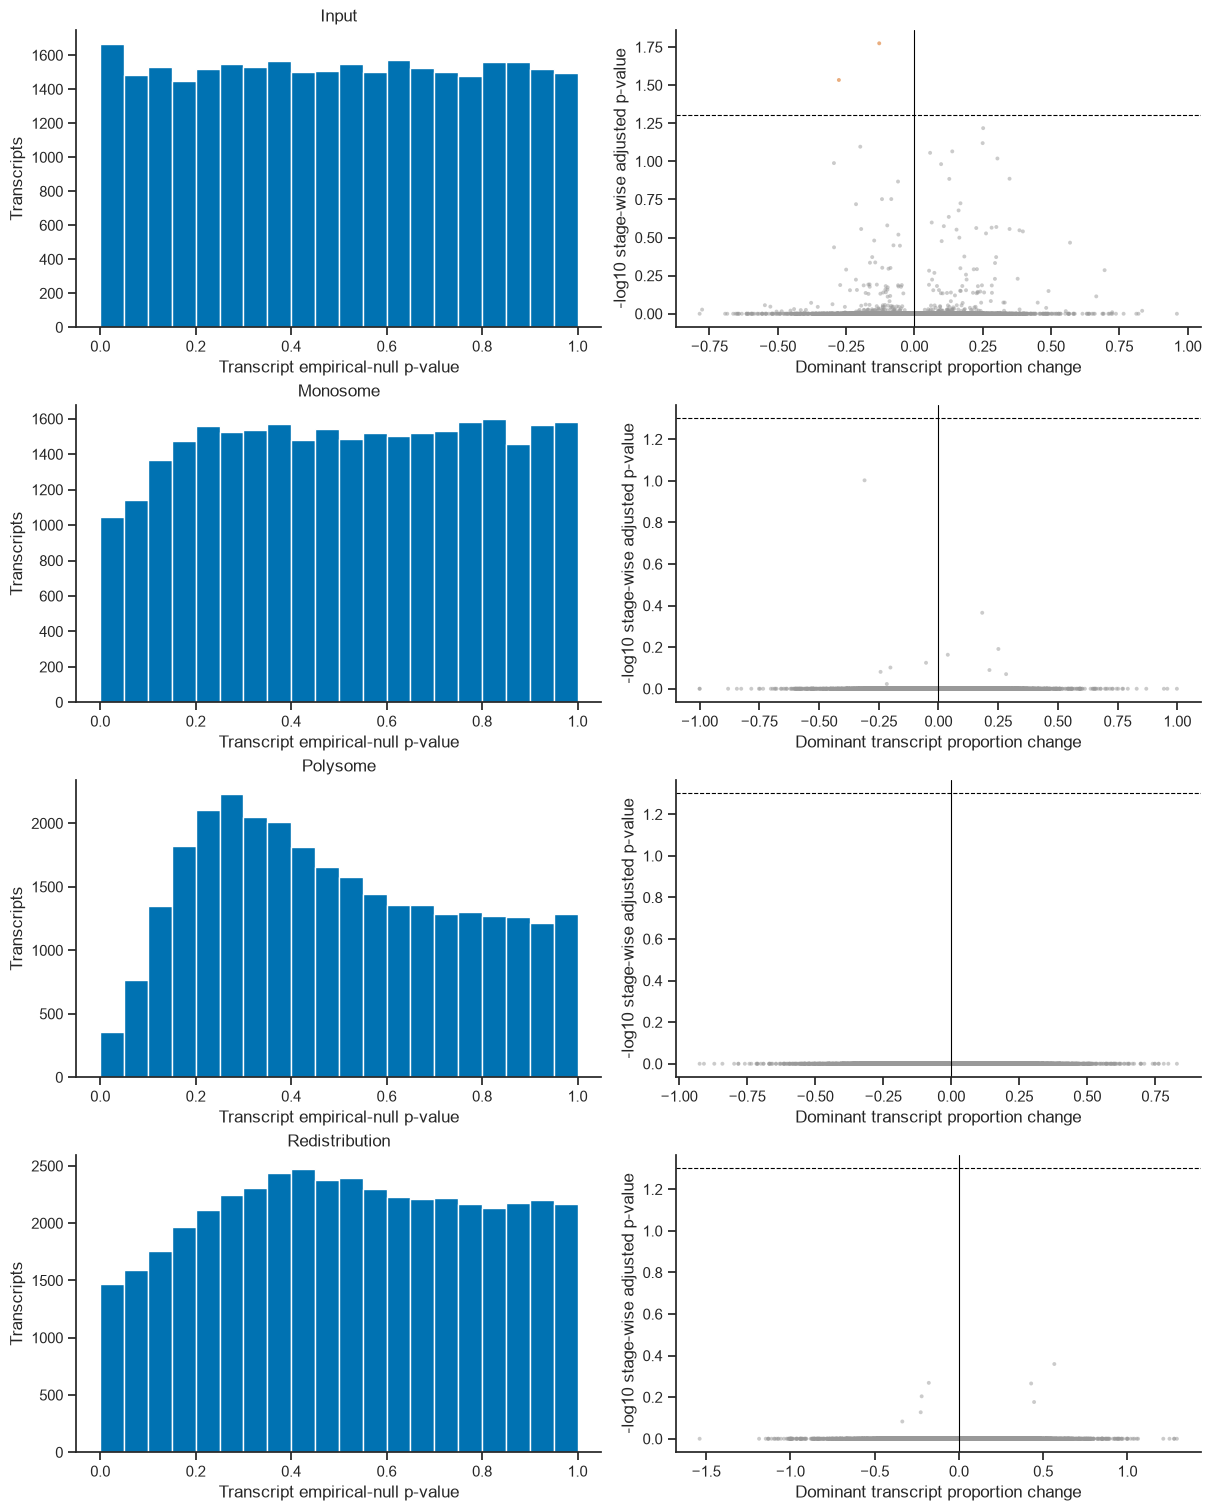

In [12]:
# Review p-value behavior and effect sizes for every DTU model.

figure, axes = plt.subplots(4, 2, figsize = (12, 15), constrained_layout = True)

for row, analysis in enumerate(ANALYSES):
    gene = gene_results[analysis]
    finite_p = transcript_results[analysis]['pValue'].dropna()
    axes[row, 0].hist(
        finite_p,
        bins = np.linspace(0, 1, 21),
        color = '#0072B2',
        edgecolor = 'white',
    )
    axes[row, 0].set(
        xlabel = 'Transcript empirical-null p-value',
        ylabel = 'Transcripts',
        title = LABELS[analysis],
    )
    colors = np.where(gene['significant'], '#D55E00', '#999999')
    significance = -np.log10(
        gene['stageAdjustedPValue'].clip(lower = np.finfo(float).tiny)
    )
    axes[row, 1].scatter(
        gene['dominantDeltaProportion'],
        significance,
        c = colors,
        s = 8,
        alpha = 0.5,
        linewidths = 0,
        rasterized = True,
    )
    axes[row, 1].axvline(0, color = 'black', linewidth = 0.8)
    axes[row, 1].axhline(
        -np.log10(ALPHA),
        color = 'black',
        linewidth = 0.8,
        linestyle = '--',
    )
    axes[row, 1].set(
        xlabel = 'Dominant transcript proportion change',
        ylabel = '-log10 stage-wise adjusted p-value',
    )

sns.despine()
plt.show()


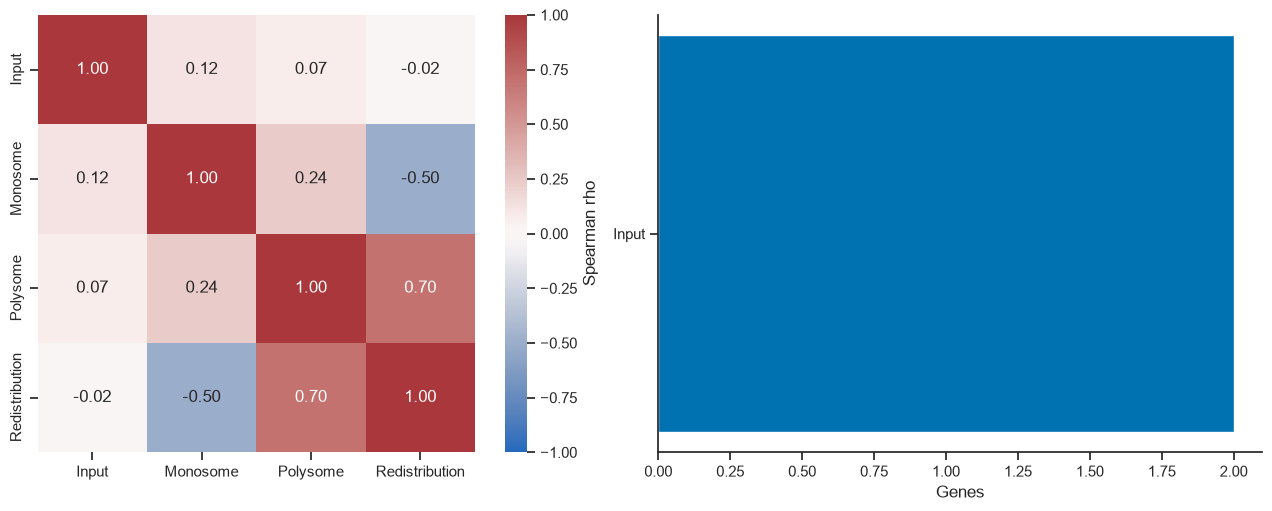

In [13]:
# Visualize cross-layer agreement and the strongest confirmed DTU genes.

figure, axes = plt.subplots(1, 2, figsize = (14, 5), constrained_layout = True)
sns.heatmap(
    correlation_matrix.rename(index = LABELS, columns = LABELS),
    annot = True,
    fmt = '.2f',
    vmin = -1,
    vmax = 1,
    center = 0,
    cmap = 'vlag',
    square = True,
    cbar_kws = {'label': 'Spearman rho'},
    ax = axes[0],
)
axes[0].set(xlabel = '', ylabel = '')

plot_overlap = gene_fdr_overlap.head(12).sort_values('genes')
axes[1].barh(
    plot_overlap['signature'],
    plot_overlap['genes'],
    color = '#0072B2',
)
axes[1].set(xlabel = 'Genes', ylabel = '')
sns.despine(ax = axes[1])
plt.show()


In [14]:
# Save complete results, designs, software provenance, and annotation features.

for analysis in ANALYSES:
    gene_results[analysis].reset_index().to_csv(
        RESULTS_DIR / f'{analysis}DtuGene.tsv',
        sep = '\t',
        index = False,
        na_rep = 'NA',
    )
    transcript_results[analysis].reset_index().to_csv(
        RESULTS_DIR / f'{analysis}DtuTranscript.tsv',
        sep = '\t',
        index = False,
        na_rep = 'NA',
    )
    dtu[analysis]['designFull'].assign(model = 'full').to_csv(
        RESULTS_DIR / f'{analysis}DtuDesignFull.tsv',
        sep = '\t',
        index = False,
    )
    dtu[analysis]['designNull'].assign(model = 'null').to_csv(
        RESULTS_DIR / f'{analysis}DtuDesignNull.tsv',
        sep = '\t',
        index = False,
    )
    shutil.copy2(
        dtu[analysis]['diagnosticPath'],
        RESULTS_DIR / f'{analysis}DtuEmpiricalDiagnostics.pdf',
    )

quantification_audit.to_csv(
    RESULTS_DIR / 'dtuQuantificationAudit.tsv',
    sep = '\t',
    index = False,
)
scaling_audit.to_csv(
    RESULTS_DIR / 'dtuScalingAudit.tsv',
    sep = '\t',
    index = False,
)
filter_summary.to_csv(
    RESULTS_DIR / 'dtuFilterSummary.tsv',
    sep = '\t',
    index = False,
)
dtu_summary.to_csv(
    RESULTS_DIR / 'dtuSummary.tsv',
    sep = '\t',
    index = False,
)
gene_comparison.reset_index().to_csv(
    RESULTS_DIR / 'dtuGeneComparison.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
transcript_comparison.reset_index().to_csv(
    RESULTS_DIR / 'dtuTranscriptComparison.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
gene_fdr_overlap.to_csv(
    RESULTS_DIR / 'dtuGeneFdrOverlap.tsv',
    sep = '\t',
    index = False,
)
layer_correlation.to_csv(
    RESULTS_DIR / 'dtuLayerCorrelation.tsv',
    sep = '\t',
    index = False,
)
dtu_candidates.to_csv(
    RESULTS_DIR / 'dtuCandidateSummary.tsv',
    sep = '\t',
    index = False,
    na_rep = 'NA',
)
warning_tables = []
for analysis, output in dtu.items():
    if not output['warnings'].empty:
        warning_tables.append(output['warnings'].assign(analysis = analysis))
dtu_warnings = (
    pd.concat(warning_tables, ignore_index = True)
    if warning_tables
    else pd.DataFrame(columns = ['warningMessage', 'count', 'analysis'])
)
dtu_warnings = dtu_warnings[['analysis', 'warningMessage', 'count']]
dtu_warnings.to_csv(
    RESULTS_DIR / 'dtuWarnings.tsv',
    sep = '\t',
    index = False,
)
version_tables = [
    dtu[analysis]['versions'].set_index('software')['version'].sort_index()
    for analysis in ANALYSES
]
if not all(version_tables[0].equals(table) for table in version_tables[1:]):
    raise ValueError('R software versions changed between DTU runs.')
software_versions = dtu['input']['versions'].copy()
software_versions.to_csv(
    RESULTS_DIR / 'dtuSoftwareVersions.tsv',
    sep = '\t',
    index = False,
)
(RESULTS_DIR / 'dtuRSessionInfo.txt').write_text(
    dtu['redistribution']['sessionInfo'],
    encoding = 'utf-8',
)

provenance = {
    'analysisUnit': 'within-gene transcript usage',
    'sourceCounts': 'Salmon transcript counts, TPM, and effective lengths',
    'countsFromAbundance': 'dtuScaledTPM',
    'inferentialReplicatesAvailable': False,
    'transcriptModel': (
        'satuRn quasi-binomial generalized linear model with empirical-null '
        'calibration'
    ),
    'geneScreen': (
        'exact DEXSeq per-gene q-value aggregation of satuRn empirical '
        'transcript p-values'
    ),
    'testDegreesOfFreedom': 'one tested model coefficient',
    'multipleTesting': 'stageR DTU procedure at 5% overall FDR',
    'zeroHandling': (
        'satuRn built-in deterministic addition of one to transcript and '
        'complementary counts'
    ),
    'convergenceGate': (
        'satuRn-equivalent quasi-binomial GLMs were independently refit; '
        'non-converged, nonfinite, and R-threshold numerical-boundary fits '
        'were converted to fit errors before testing'
    ),
    'redistributionFullModel': (
        '~ participantId + fraction + pmInteraction'
    ),
    'redistributionNullModel': '~ participantId + fraction',
    'pmInteraction': 'ASD indicator multiplied by polysome indicator',
    'seed': 1077,
    'workers': N_WORKERS,
    'methodReferences': {
        'tximport': 'https://doi.org/10.12688/f1000research.7563.1',
        'satuRn': 'https://doi.org/10.12688/f1000research.51749.2',
        'DEXSeq': 'https://doi.org/10.1101/gr.133744.111',
        'stageR': 'https://doi.org/10.1186/s13059-017-1277-0',
    },
    'software': software_versions.to_dict(orient = 'records'),
}
(RESULTS_DIR / 'dtuProvenance.json').write_text(
    json.dumps(provenance, indent = 2),
    encoding = 'utf-8',
)

resolved_work = WORK_DIR.resolve()
resolved_temp = Path(tempfile.gettempdir()).resolve()
if resolved_temp not in resolved_work.parents:
    raise RuntimeError(
        'Refusing to remove a work directory outside the system temp path.'
    )
shutil.rmtree(resolved_work)
